# Fashion-MNIST: master AML comparison

**Anant Jain · Phase 1 · Team T112**

Compare Logistic Regression, k-NN, Random Forest, and Linear SVM on Pixels (784 features) and HOG (324 features). This notebook only reads the eight model owners' JSON reports. It does not train models or access the held-out test images.

Protocol: stratified 48,000/12,000 development split, seed 42; select hyperparameters on validation data; refit on the full 60,000 training images and report on the official 10,000 test images. Run all cells after the model contributions are merged. Missing results remain pending; no example scores are substituted.

In [1]:
import json
from numbers import Real
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from aml.data import CLASS_NAMES

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "pyproject.toml").is_file() and (p / "docs/team").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or notebooks/ directory.")
RESULTS_DIR = ROOT / "reports" / "results"
MODELS = {
    "logreg": "Logistic Regression", "knn": "k-NN",
    "rf": "Random Forest", "svm": "Linear SVM",
}
FEATURES = {"pixels": "Pixels", "hog": "HOG"}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

## Check the eight contributions

The schema is defined in `docs/team/README.md`. The legacy `parameter_count` field stores **weights including intercepts** for linear models, **total nodes** for forests, and **stored feature memory in MiB** for k-NN. These are different complexity measures. k-NN memory follows its guide's division by 1,048,576, rather than decimal MB.

Latency measures batch `predict()` time per image. Compare it only when hardware, batch size, preprocessing, and timing protocol match; separately computed feature extraction is excluded. The current k-NN guide uses a single batched timing rather than the shared median timing, so its reported latency is not strictly comparable until measured with a common protocol.

In [2]:
REQUIRED = {
    "model", "features", "best_params", "train_n", "val_n", "test_n",
    "validation_accuracy", "validation_macro_f1", "test_accuracy", "test_macro_f1",
    "per_class_recall", "parameter_count", "inference_latency_ms_per_image",
}
SCORES = ("validation_accuracy", "validation_macro_f1", "test_accuracy", "test_macro_f1")


def valid_number(value, low=0, high=None):
    return (isinstance(value, Real) and not isinstance(value, bool)
            and np.isfinite(value) and value >= low and (high is None or value <= high))


def validate_result(result, model, features):
    if not isinstance(result, dict):
        raise ValueError("Expected a JSON object.")
    missing = REQUIRED - result.keys()
    if missing:
        raise ValueError(f"Missing fields: {', '.join(sorted(missing))}")
    if (result["model"], result["features"]) != (model, features):
        raise ValueError("Model/features do not match the filename.")
    if not isinstance(result["best_params"], dict):
        raise ValueError("best_params must be an object.")
    if any(not valid_number(result[key], high=1) for key in SCORES):
        raise ValueError("Accuracy and F1 must be finite values in [0, 1].")
    recalls = result["per_class_recall"]
    if not isinstance(recalls, list) or len(recalls) != 10 or any(
        not valid_number(value, high=1) for value in recalls
    ):
        raise ValueError("Expected ten per-class recalls in [0, 1].")
    for key in ("parameter_count", "inference_latency_ms_per_image"):
        if not valid_number(result[key]):
            raise ValueError(f"{key} must be finite and nonnegative.")
    # The shared schema records development train_n=48000; some owners may
    # record the final refit size 60000. Accept both, and retain the distinction.
    if result["train_n"] not in (48000, 60000) or result["val_n"] != 12000 or result["test_n"] != 10000:
        raise ValueError("Expected train_n 48000 or 60000, val_n 12000, test_n 10000.")
    if model != "knn" and result["parameter_count"] % 1:
        raise ValueError("Weight/node counts must be integers.")
    return result


records, status = [], []
for model in MODELS:
    for features in FEATURES:
        path = RESULTS_DIR / f"{model}_{features}.json"
        state = "Missing"
        if path.is_file():
            try:
                record = validate_result(json.loads(path.read_text()), model, features)
                records.append(record)
                state = "Ready"
            except (OSError, ValueError, TypeError) as exc:
                state = f"Invalid: {exc}"
        status.append({"File": path.name, "Status": state})

status_table = pd.DataFrame(status)
display(status_table)
complete = len(records) == 8
if not complete:
    display(Markdown(f"**Pending:** {len(records)}/8 valid results. Final comparison will appear when all eight files are ready."))

,File,Status
0,logreg_pixels.json,Ready
1,logreg_hog.json,Ready
2,knn_pixels.json,Ready
3,knn_hog.json,Ready
4,rf_pixels.json,Ready
5,rf_hog.json,Ready
6,svm_pixels.json,Ready
7,svm_hog.json,Ready


## Master summary table

Validation scores describe hyperparameter selection; test scores describe the selected model after refitting. Keep the test set out of tuning. The comparison below waits for all eight valid reports.

In [3]:
summary = pd.DataFrame()
results = pd.DataFrame(records)
if complete:
    rows = []
    for result in records:
        model = result["model"]
        value = result["parameter_count"]
        complexity = (f"{value:.2f} MiB stored features" if model == "knn"
                      else f"{int(value):,} {'nodes' if model == 'rf' else 'weights'}")
        rows.append({
            "Model": MODELS[model], "Feature Set": FEATURES[result["features"]],
            "Val Accuracy": result["validation_accuracy"],
            "Test Accuracy": result["test_accuracy"],
            "Test Macro F1": result["test_macro_f1"],
            "Complexity": complexity,
            "Latency (ms/img)": result["inference_latency_ms_per_image"],
        })
    summary = pd.DataFrame(rows)
    display(summary.style.format({
        "Val Accuracy": "{:.2%}", "Test Accuracy": "{:.2%}",
        "Test Macro F1": "{:.2%}", "Latency (ms/img)": "{:.4f}",
    }).hide(axis="index"))

Model,Feature Set,Val Accuracy,Test Accuracy,Test Macro F1,Complexity,Latency (ms/img)
Logistic Regression,Pixels,85.97%,84.32%,84.24%,"7,850 weights",0.0007
Logistic Regression,HOG,85.51%,84.55%,84.49%,"3,250 weights",0.0004
k-NN,Pixels,86.03%,85.41%,85.40%,179.44 MiB stored features,0.2741
k-NN,HOG,84.75%,83.84%,83.85%,74.16 MiB stored features,0.0980
Random Forest,Pixels,88.57%,87.43%,87.31%,"1,693,570 nodes",0.0264
Random Forest,HOG,84.98%,84.35%,84.30%,"2,458,016 nodes",0.0291
Linear SVM,Pixels,85.72%,83.80%,83.57%,"7,850 weights",0.0013
Linear SVM,HOG,85.31%,84.23%,84.06%,"3,250 weights",0.0006


## Pixels versus HOG

Both panels use the same 0–100% scale. These are the reported test results; they are not new evaluations.

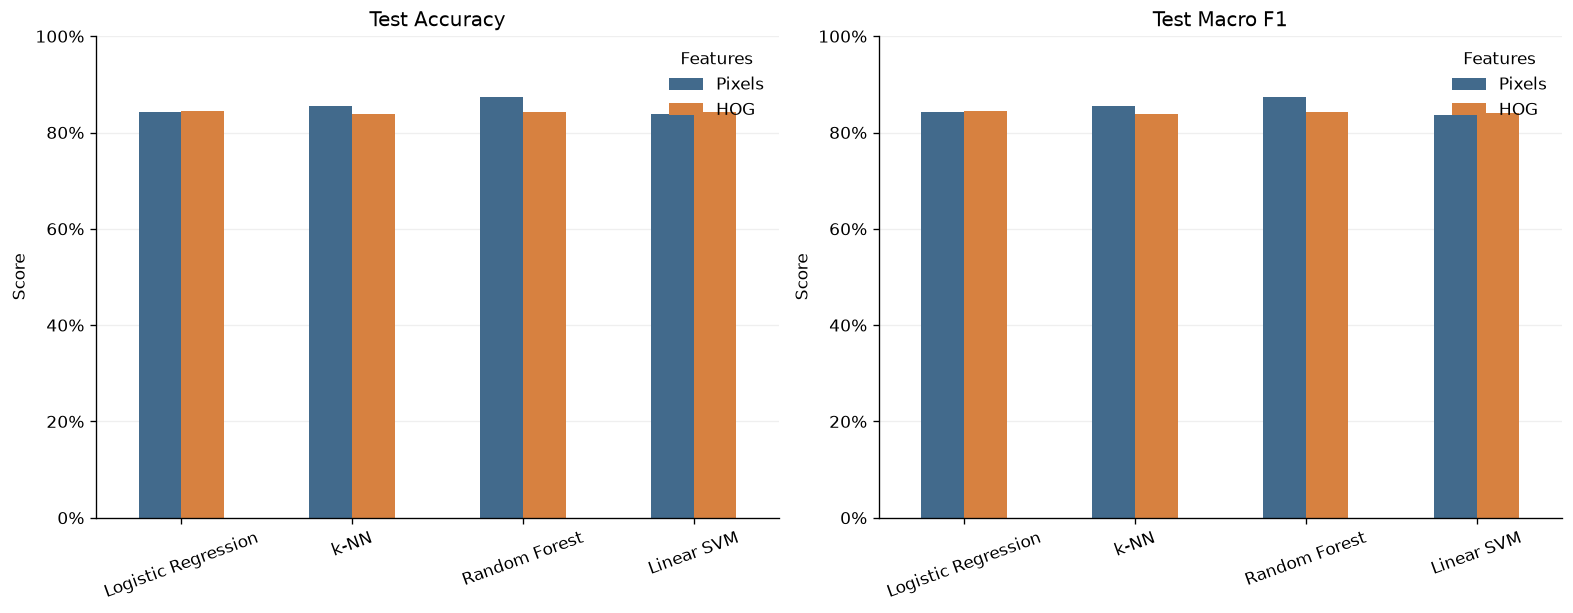

In [4]:
if complete:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    for ax, metric in zip(axes, ("Test Accuracy", "Test Macro F1")):
        values = summary.pivot(index="Model", columns="Feature Set", values=metric)
        values = values.reindex(index=list(MODELS.values()), columns=list(FEATURES.values()))
        values.plot.bar(ax=ax, color=["#426A8C", "#D78140"], rot=20)
        ax.set(title=metric, xlabel="", ylabel="Score", ylim=(0, 1))
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.legend(title="Features", frameon=False)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
    plt.show()

## Findings from the submitted results

HOG encodes local edge orientations and may help linear classifiers separate shapes while reducing dimension from 784 to 324. Whether it improves either linear model must be established by the scores below. The expected 88–89% baseline ceiling and difficulty with Shirt are hypotheses to check, rather than fixed conclusions.

In [5]:
if complete:
    indexed = results.set_index(["model", "features"])
    lines = []
    for model, label in MODELS.items():
        pixels = indexed.loc[(model, "pixels"), "test_accuracy"]
        hog = indexed.loc[(model, "hog"), "test_accuracy"]
        lines.append(f"- **{label}:** HOG changes test accuracy by {(hog - pixels) * 100:+.2f} percentage points versus Pixels.")
    best = results.loc[results["test_macro_f1"].idxmax()]
    lines.append(
        f"- **Highest reported test macro F1:** {MODELS[best['model']]} / {FEATURES[best['features']]} "
        f"({best['test_macro_f1']:.2%}), with test accuracy {best['test_accuracy']:.2%}."
    )
    lines.append(
        f"- **Observed test accuracy range:** {results['test_accuracy'].min():.2%}–"
        f"{results['test_accuracy'].max():.2%}. This is the range for these configurations, not a proven ceiling."
    )
    mean_recall = np.array(results["per_class_recall"].tolist()).mean(axis=0)
    weakest = int(mean_recall.argmin())
    lines.append(
        f"- **Garment errors:** mean Shirt recall is {mean_recall[6]:.2%}; "
        f"the lowest mean recall is {CLASS_NAMES[weakest]} ({mean_recall[weakest]:.2%}). "
        "Inspect the model confusion matrices and Utkarsh's error report before attributing specific confusions."
    )
    lines.append(
        "- **Phase 2:** compare a small CNN against these measured baselines using the same official splits. "
        "Test whether learned features improve recall for visually similar garments."
    )
    display(Markdown("\n".join(lines)))
else:
    display(Markdown("Final findings are pending the eight model reports. Re-run all cells after they are merged."))

- **Logistic Regression:** HOG changes test accuracy by +0.23 percentage points versus Pixels.
- **k-NN:** HOG changes test accuracy by -1.57 percentage points versus Pixels.
- **Random Forest:** HOG changes test accuracy by -3.08 percentage points versus Pixels.
- **Linear SVM:** HOG changes test accuracy by +0.43 percentage points versus Pixels.
- **Highest reported test macro F1:** Random Forest / Pixels (87.31%), with test accuracy 87.43%.
- **Observed test accuracy range:** 83.80%–87.43%. This is the range for these configurations, not a proven ceiling.
- **Garment errors:** mean Shirt recall is 57.71%; the lowest mean recall is Shirt (57.71%). Inspect the model confusion matrices and Utkarsh's error report before attributing specific confusions.
- **Phase 2:** compare a small CNN against these measured baselines using the same official splits. Test whether learned features improve recall for visually similar garments.